In [1]:
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder,get_acronym

eps = 1E-7
rcpsize = 12
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['o','x','h','^','s','*']
_linestyles = ['-','--','dotted']
plot_id = 0

depths = {"deepseek":61,
          "llama":32}

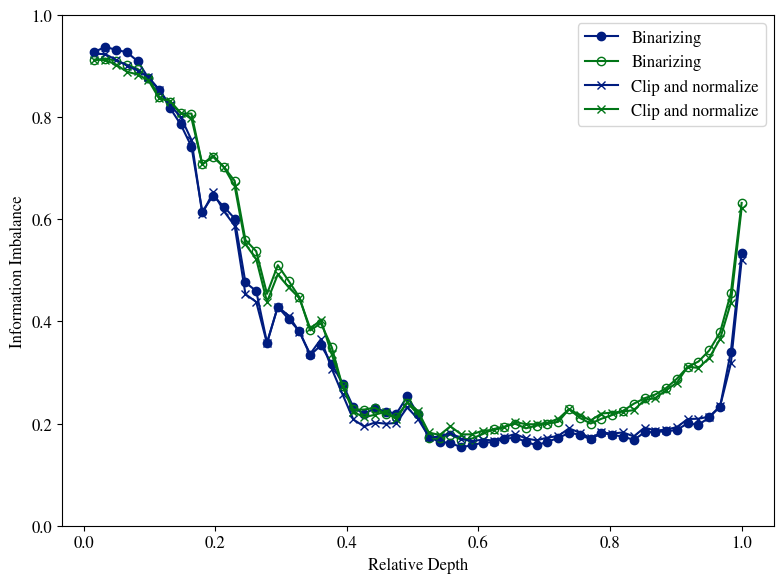

In [6]:
models = [
          'deepseek',
          # 'llama',
          ]
model = models[0] ; model_id = 0

mask = 2
language_pairs = [('english','spanish'),
                  # ('german','hungarian'),
                  ]
n_files = 500
batch_size = 10 
Ns = batch_size*n_files

n_tokens_list = [20]

fig,ax = plt.subplots(1,1,
                            figsize=(8,6),
                            # constrained_layout=True,
                            )

k_list = [10]
min_token_length = 40
Nbits_list = [0,1]

seed_list = range(1)
for Nbits_id, Nbits in enumerate(Nbits_list):
  for k_id,k in enumerate(k_list):
    for avg in [0]:
      avg_tokens_II = avg
      avg_tokens_A = avg_tokens_II
      for n_tokens_id,n_tokens in enumerate(n_tokens_list):
          IIs = np.zeros(shape=(len(seed_list),2,depths[model]))
          A_layer_ids = np.arange(1,depths[model]+1)
          B_layer_ids = np.arange(1,depths[model]+1)

          if model == 'deepseek':
            _model = 'V3'
          elif model =='llama':
            _model = 'L3'
          for language_pair_id, language_pair in enumerate(language_pairs):
            for seed_id, seed in enumerate(seed_list):
              (languageA,languageB) = language_pair
              II_folder = makefolder(base=f'./results/santiago/',
                                        batch_shuffle = 0,
                                        modelA=model,
                                        modelB=model,
                                        n_files=n_files,
                                        min_token_length=min_token_length,
                                        languageA=languageA,
                                        languageB=languageB,
                                        mask=mask,
                                        k=k,
                                        Nbits=Nbits,
                                        seed=seed,
                                        )
              alignment = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_A}_alignment.npy')
              IIs[seed_id,0,:] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_II}_AB.npy').diagonal()
              IIs[seed_id,1,:] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_II}_BA.npy').diagonal()

            mfc = 'none' if Nbits == 0 else colors[0]
            lbl = f'Binarizing' if Nbits == 0 else f'Clip and normalize'
            ax.plot(A_layer_ids / depths[model],
                    IIs[:, 0, :].mean(axis=0),
                    label=lbl,
                    linestyle=_linestyles[model_id],
                    color=colors[0],
                    marker=markers[Nbits],               # Circle marker
                    markerfacecolor=colors[0],   # Open (hollow) circle
                    markeredgecolor=colors[0],# Outline color same as line
                    )


            lbl = f'Binarizing' if Nbits == 0 else f'Clip and normalize'
            ax.plot(A_layer_ids / depths[model],
                    IIs[:, 1, :].mean(axis=0),
                    label=lbl,
                    linestyle=_linestyles[model_id],
                    color=colors[1],
                    marker=markers[Nbits],               # Circle marker
                    markerfacecolor='none',   # Open (hollow) circle
                    markeredgecolor=colors[1],# Outline color same as line
                    )
          figsfolder = makefolder(base=f'./results/figs/translations/spin_vs_float/',
                                  create_folder=True,
                                  n_files=n_files,
                                  )
          
          np.savetxt(figsfolder+f'{model}_{languageA}_{languageB}_{Nbits}.txt',
                     np.array([A_layer_ids,IIs[:,0,:].mean(axis=0)]).T)
          np.savetxt(figsfolder+f'{model}_{languageB}_{languageA}_{Nbits}.txt',
                     np.array([A_layer_ids,IIs[:,1,:].mean(axis=0)]).T)
          # box = ax.get_position()
          # ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
          # ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

          ax.set_xlabel('Relative Depth')
          ax.set_ylabel('Information Imbalance')
          ax.set_ylim(0,1)
          ax.legend(loc='upper right')
          # ax.set_title(f'DeepSeek-V3')
  fig.savefig(f'{figsfolder}spins_vs_floats{n_tokens}.pdf',
                bbox_inches='tight',
                )